# Task 6 — Model Evaluation

**Saiket Systems | Machine Learning Internship**

Objective: assess the trained churn classifier on a held-out test set using accuracy, precision, recall, F1-score, and ROC-AUC, as required by the internship brief.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

HERE = Path.cwd().resolve()
ROOT = next((p for p in [HERE, *HERE.parents] if (p / "Dataset").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find Dataset folder. Open this notebook inside Saiket_ML_Internship.")
DATA_PATH = ROOT / "Dataset" / "Telco_Customer_Churn_Dataset.csv"
df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True), errors="coerce"
)
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop_duplicates().copy()
y = df["Churn"].map({"No": 0, "Yes": 1})


## 1. Recreate the selected features and test split

This notebook is self-contained: it rebuilds the same 80/20 stratified split using `random_state=42` and trains the specified model before evaluating it on the held-out test set.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)

selected_features = ["Contract", "MonthlyCharges", "tenure"]
X = pd.get_dummies(df[selected_features], columns=["Contract"], drop_first=True, dtype=int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
model = RandomForestClassifier(
    n_estimators=300, random_state=42, class_weight="balanced",
    min_samples_leaf=2, n_jobs=-1
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
print("Test set prepared:", X_test.shape)


Test set prepared: (1409, 4)


## 2. Calculate evaluation metrics

In [3]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
}
metrics_df = pd.DataFrame({"Metric": list(metrics.keys()), "Score": list(metrics.values())})
display(metrics_df.style.format({"Score": "{:.4f}"}))


,Metric,Score
0,Accuracy,0.7417
1,Precision,0.5105
2,Recall,0.6524
3,F1-score,0.5728
4,ROC-AUC,0.8011


## 3. Classification report and confusion matrix

              precision    recall  f1-score   support

    No churn       0.86      0.77      0.81      1035
       Churn       0.51      0.65      0.57       374

    accuracy                           0.74      1409
   macro avg       0.69      0.71      0.69      1409
weighted avg       0.77      0.74      0.75      1409



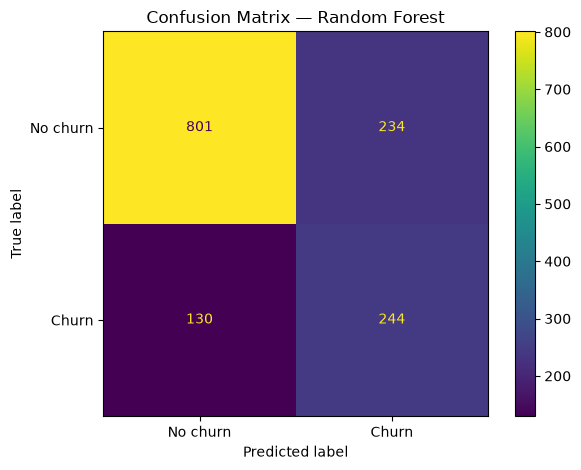

In [4]:
print(classification_report(
    y_test, y_pred, labels=[0, 1], target_names=["No churn", "Churn"], zero_division=0
))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred, labels=[0, 1]),
    display_labels=["No churn", "Churn"]
).plot()
plt.title("Confusion Matrix — Random Forest")
plt.tight_layout()
plt.show()


## 4. ROC curve

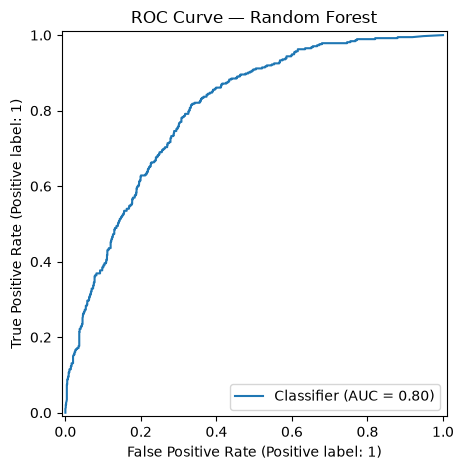

In [5]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve — Random Forest")
plt.tight_layout()
plt.show()


## 5. Interpret the results

In [6]:
print("Model: Random Forest")
print("Features: Contract, MonthlyCharges, tenure")
print(f"Accuracy:  {metrics['Accuracy']:.4f}")
print(f"Precision: {metrics['Precision']:.4f}")
print(f"Recall:    {metrics['Recall']:.4f}")
print(f"F1-score:  {metrics['F1-score']:.4f}")
print(f"ROC-AUC:   {metrics['ROC-AUC']:.4f}")
print("\\nInterpretation guide:")
print("- Accuracy: fraction of all predictions that are correct.")
print("- Precision: among predicted churners, fraction who actually churned.")
print("- Recall: among actual churners, fraction identified by the model.")
print("- F1-score: harmonic mean of precision and recall.")
print("- ROC-AUC: ability to rank churners above non-churners across thresholds.")
print("\\nUse recall and precision together when planning retention campaigns; a default 0.50 threshold may not be optimal.")


Model: Random Forest
Features: Contract, MonthlyCharges, tenure
Accuracy:  0.7417
Precision: 0.5105
Recall:    0.6524
F1-score:  0.5728
ROC-AUC:   0.8011
\nInterpretation guide:
- Accuracy: fraction of all predictions that are correct.
- Precision: among predicted churners, fraction who actually churned.
- Recall: among actual churners, fraction identified by the model.
- F1-score: harmonic mean of precision and recall.
- ROC-AUC: ability to rank churners above non-churners across thresholds.
\nUse recall and precision together when planning retention campaigns; a default 0.50 threshold may not be optimal.
